# Proyek Analisis Data: E-Commerce Public Dataset (Brazilian E-Commerce / Olist)
- **Nama:** Gilbert Finsen Zakaria Lian
- **Email:** glian6020@gmail.com
- **ID Dicoding:** ds269b6y0676

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam:

* **Specific (Spesifik):** Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda.
* **Measurable (Terukur):** Pertanyaan harus bisa dijawab dengan angka atau metrik yang konkret.
* **Action-Oriented (Berorientasi Aksi):** Hasil analisis harus mampu memberikan arahan tindakan nyata bagi pemangku kepentingan (*stakeholders*).
* **Relevant (Relevan):** Hasil analisis sejalan dengan tujuan utama efisiensi bisnis atau penyelesaian masalah platform.
* **Time-bound (Terikat Waktu):** Dibatasi pada rentang waktu yang jelas agar analisis memiliki konteks yang tepat.

### Perumusan Pertanyaan Bisnis (SMART):

- **Pertanyaan 1:**
  > **Kategori produk apa saja yang menghasilkan total pendapatan (*revenue*) tertinggi dan terendah pada platform e-commerce Olist sepanjang periode 2017 hingga 2018, dan bagaimana dinamika penjualannya?**
  - **Specific:** Menargetkan identifikasi 5 kategori produk teratas dan 5 kategori terbawah berdasarkan total revenue di platform Olist.
  - **Measurable:** Diukur dengan metrik total order value / GMV dalam mata uang Brazilian Real (BRL) dan total unit/order terjual.
  - **Action-Oriented:** Manajemen dapat mengoptimalkan alokasi inventaris, kurasi kampanye pemasaran beranggaran tinggi pada kategori bintang, serta mengevaluasi kelanjutan kategori berkinerja rendah.
  - **Relevant:** Berdampak langsung pada strategi optimalisasi portofolio produk dan pertumbuhan pendapatan (*revenue growth*).
  - **Time-bound:** Dibatasi secara spesifik pada transaksi tahun 2017 hingga 2018.

- **Pertanyaan 2:**
  > **Bagaimana pengaruh selisih waktu pengiriman aktual terhadap estimasi pengiriman (*delivery delay*) terhadap skor kepuasan pelanggan (*review score*) pada pesanan berstatus *delivered* selama tahun 2017-2018?**
  - **Specific:** Mengukur perbedaan skor kepuasan pelanggan antara pesanan yang tiba tepat waktu (*on-time/early*) vs pesanan yang mengalami keterlambatan (*late*).
  - **Measurable:** Diukur dengan rata-rata *review score* (skala 1 hingga 5) dan proporsi distribusi bintang ulasan.
  - **Action-Oriented:** Tim operasional logistik dapat mengevaluasi performa kurir pihak ketiga, memperbaiki perhitungan estimasi waktu tiba (SLA), dan membuat mekanisme proaktif kompensasi untuk pesanan tertunda.
  - **Relevant:** Ketepatan pengiriman merupakan faktor kunci loyalitas pelanggan dan *Net Promoter Score* (NPS) e-commerce.
  - **Time-bound:** Dianalisis pada transaksi pesanan delivered sepanjang periode 2017 hingga 2018.

## Import Semua Packages/Library yang Digunakan

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import os

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.family'] = 'sans-serif'
print("Libraries imported successfully!")

Libraries imported successfully!


## Data Wrangling

### Gathering Data
Pada tahap ini, seluruh berkas dataset yang diperlukan untuk analisis dimuat ke dalam DataFrame Pandas.

In [2]:
# Memuat semua tabel yang relevan dari direktori data/
customers_df = pd.read_csv('data/customers_dataset.csv')
orders_df = pd.read_csv('data/orders_dataset.csv')
order_items_df = pd.read_csv('data/order_items_dataset.csv')
order_payments_df = pd.read_csv('data/order_payments_dataset.csv')
order_reviews_df = pd.read_csv('data/order_reviews_dataset.csv')
products_df = pd.read_csv('data/products_dataset.csv')
product_translation_df = pd.read_csv('data/product_category_name_translation.csv')
sellers_df = pd.read_csv('data/sellers_dataset.csv')
geolocation_df = pd.read_csv('data/geolocation_dataset.csv')

print("Ukuran dataset:")
print(f"- customers_df: {customers_df.shape}")
print(f"- orders_df: {orders_df.shape}")
print(f"- order_items_df: {order_items_df.shape}")
print(f"- order_payments_df: {order_payments_df.shape}")
print(f"- order_reviews_df: {order_reviews_df.shape}")
print(f"- products_df: {products_df.shape}")
print(f"- product_translation_df: {product_translation_df.shape}")
print(f"- sellers_df: {sellers_df.shape}")
print(f"- geolocation_df: {geolocation_df.shape}")

Ukuran dataset:
- customers_df: (99441, 5)
- orders_df: (99441, 8)
- order_items_df: (112650, 7)
- order_payments_df: (103886, 5)
- order_reviews_df: (99224, 7)
- products_df: (32951, 9)
- product_translation_df: (71, 2)
- sellers_df: (3095, 4)
- geolocation_df: (1000163, 5)


In [3]:
# Menampilkan cuplikan data teratas untuk tabel utama
orders_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


**Insight:**
- Terdapat 9 tabel terpisah yang saling berelasi melalui kunci relasional (`order_id`, `customer_id`, `product_id`, `seller_id`).
- Tabel `orders_df` mencatat 99.441 transaksi pesanan dengan rentang atribut waktu mulai dari pemesanan hingga penerimaan oleh pelanggan.
- Tabel `order_items_df` mencatat 112.650 item transaksi yang terikat dengan produk dan nilai nominal harga (*price*) serta ongkos kirim (*freight_value*).

### Assessing Data
Pada tahap ini, dilakukan pemeriksaan kualitas data guna mengidentifikasi *missing values*, *duplicate data*, ketidaksesuaian tipe data, serta nilai *outlier* / *inaccurate*.

In [4]:
print("=== 1. Pemeriksaan Missing Values ===")
print("orders_df missing values:")
print(orders_df.isna().sum()[orders_df.isna().sum() > 0])
print("\nproducts_df missing values:")
print(products_df.isna().sum()[products_df.isna().sum() > 0])
print("\norder_reviews_df missing values:")
print(order_reviews_df.isna().sum()[order_reviews_df.isna().sum() > 0])

=== 1. Pemeriksaan Missing Values ===
orders_df missing values:
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64

products_df missing values:
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

order_reviews_df missing values:
review_comment_title      87656
review_comment_message    58247
dtype: int64


In [5]:
print("=== 2. Pemeriksaan Duplikasi Data ===")
print(f"Duplikasi orders_df: {orders_df.duplicated().sum()}")
print(f"Duplikasi order_items_df: {order_items_df.duplicated().sum()}")
print(f"Duplikasi customers_df: {customers_df.duplicated().sum()}")
print(f"Duplikasi order_reviews_df (baris persis): {order_reviews_df.duplicated().sum()}")
print(f"Duplikasi order_id pada order_reviews_df: {order_reviews_df['order_id'].duplicated().sum()}")
print(f"Duplikasi geolocation_df: {geolocation_df.duplicated().sum()}")

=== 2. Pemeriksaan Duplikasi Data ===
Duplikasi orders_df: 0
Duplikasi order_items_df: 0
Duplikasi customers_df: 0
Duplikasi order_reviews_df (baris persis): 0
Duplikasi order_id pada order_reviews_df: 551


Duplikasi geolocation_df: 261831


In [6]:
print("=== 3. Pemeriksaan Tipe Data Kolom Waktu pada orders_df ===")
print(orders_df.dtypes[['order_purchase_timestamp', 'order_approved_at', 
                        'order_delivered_carrier_date', 'order_delivered_customer_date', 
                        'order_estimated_delivery_date']])

=== 3. Pemeriksaan Tipe Data Kolom Waktu pada orders_df ===
order_purchase_timestamp         str
order_approved_at                str
order_delivered_carrier_date     str
order_delivered_customer_date    str
order_estimated_delivery_date    str
dtype: object


In [7]:
print("=== 4. Pemeriksaan Nilai Statistik & Anomali Geolocation ===")
print(geolocation_df[['geolocation_lat', 'geolocation_lng']].describe())

=== 4. Pemeriksaan Nilai Statistik & Anomali Geolocation ===
       geolocation_lat  geolocation_lng
count     1.000163e+06     1.000163e+06
mean     -2.117615e+01    -4.639054e+01
std       5.715866e+00     4.269748e+00
min      -3.660537e+01    -1.014668e+02
25%      -2.360355e+01    -4.857317e+01
50%      -2.291938e+01    -4.663788e+01
75%      -1.997962e+01    -4.376771e+01
max       4.506593e+01     1.211054e+02


**Steps to Take (Rencana Tindakan Pembersihan Data):**
1. **Perbaikan Tipe Data:** Seluruh kolom waktu pada `orders_df` (`order_purchase_timestamp`, `order_approved_at`, `order_delivered_carrier_date`, `order_delivered_customer_date`, `order_estimated_delivery_date`) yang masih bertipe `object` (string) harus dikonversi menjadi tipe data `datetime64[ns]`.
2. **Penanganan Missing Values:** 
   - Nilai null pada `order_delivered_customer_date` terjadi pada pesanan yang belum selesai (*shipped*, *canceled*, *processing*). Untuk analisis logistik dan kepuasan pelanggan, kita akan memfilter pesanan dengan status `delivered`.
   - Pada `products_df`, terdapat 610 produk dengan `product_category_name` bernilai null. Nilai ini akan diimputasi dengan nilai kategori `'others'`.
   - Menggabungkan translasi nama kategori bahasa Portugis ke bahasa Inggris dari `product_translation_df`.
3. **Penanganan Duplikasi:**
   - Pada `order_reviews_df`, terdapat 551 pesanan yang memiliki lebih dari satu ulasan. Kita akan mengurutkan berdasarkan `review_answer_timestamp` dan mempertahankan ulasan paling terkini untuk setiap `order_id`.
   - Pada `geolocation_df`, terdapat 261.831 baris duplikat yang akan dihapus, serta menyaring koordinat yang berada di luar batas geografis Brazil (Lat: -33.75 s/d 5.27, Lng: -73.98 s/d -34.79).

### Cleaning Data
Pada tahap ini, langkah-langkah pembersihan data yang telah dirumuskan pada tahap *Assessing Data* dijalankan.

In [8]:
# 1. Konversi Tipe Data Waktu ke Datetime
time_cols = [
    'order_purchase_timestamp', 'order_approved_at', 
    'order_delivered_carrier_date', 'order_delivered_customer_date', 
    'order_estimated_delivery_date'
]
for col in time_cols:
    orders_df[col] = pd.to_datetime(orders_df[col])

print("Tipe data kolom waktu setelah perbaikan:")
print(orders_df[time_cols].dtypes)

Tipe data kolom waktu setelah perbaikan:
order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object


In [9]:
# 2. Imputasi dan Translasi Kategori Produk
# Gabungkan dengan translasi bahasa inggris
products_clean = products_df.merge(product_translation_df, on='product_category_name', how='left')
# Imputasi kategori yang tidak memiliki padanan / null menjadi 'others'
products_clean['product_category_name_english'] = products_clean['product_category_name_english'].fillna('others')

print(f"Jumlah missing values pada product_category_name_english: {products_clean['product_category_name_english'].isna().sum()}")

Jumlah missing values pada product_category_name_english: 0


In [10]:
# 3. Pembersihan Duplikasi pada Ulasan (Reviews)
order_reviews_clean = order_reviews_df.sort_values('review_answer_timestamp').drop_duplicates(subset=['order_id'], keep='last')
print(f"Jumlah baris ulasan unik per pesanan: {len(order_reviews_clean)} (duplikat tersisa: {order_reviews_clean['order_id'].duplicated().sum()})")

Jumlah baris ulasan unik per pesanan: 98673 (duplikat tersisa: 0)


In [11]:
# 4. Pembersihan Data Geolocation
geolocation_clean = geolocation_df.drop_duplicates()
# Filter batas koordinat geografis Brazil
geolocation_clean = geolocation_clean[
    (geolocation_clean['geolocation_lat'] >= -33.75) & (geolocation_clean['geolocation_lat'] <= 5.27) &
    (geolocation_clean['geolocation_lng'] >= -73.98) & (geolocation_clean['geolocation_lng'] <= -34.79)
]
print(f"Baris geolocation bersih: {geolocation_clean.shape[0]} (berhasil membuang duplikat dan outlier luar negeri)")

Baris geolocation bersih: 738299 (berhasil membuang duplikat dan outlier luar negeri)


**Insight:**
- Seluruh kolom datetime telah berhasil dikonversi ke tipe data waktu standar sehingga memungkinkan perhitungan durasi, selisih hari, dan pemfilteran periode waktu.
- Kategori produk telah diterjemahkan ke bahasa Inggris secara seragam dan nilai yang hilang telah diimputasi dengan `'others'`.
- Data review telah dijamin unik per pesanan (1 order = 1 review representatif).
- Data geografis telah dibersihkan dari 261 ribu data redundan dan koordinat di luar wilayah Brazil.

## Exploratory Data Analysis (EDA)
Pada tahap ini, dilakukan eksplorasi statistik, agregasi data, serta pembentukan metrik turunan guna menjawab kedua pertanyaan bisnis utama.

### 1. Eksplorasi Penggabungan Data (Data Merging)
Menggabungkan tabel transaksi, item, produk, pelanggan, dan ulasan ke dalam satu DataFrame komprehensif.

In [12]:
# Menggabungkan item pesanan dengan produk
items_with_prod = order_items_df[['order_id', 'order_item_id', 'product_id', 'price', 'freight_value']].merge(
    products_clean[['product_id', 'product_category_name_english']], 
    on='product_id', 
    how='left'
)

# Menggabungkan dengan orders
full_df = orders_df.merge(items_with_prod, on='order_id', how='inner')

# Menggabungkan dengan customers
full_df = full_df.merge(
    customers_df[['customer_id', 'customer_unique_id', 'customer_city', 'customer_state']], 
    on='customer_id', 
    how='left'
)

# Menggabungkan dengan reviews
full_df = full_df.merge(
    order_reviews_clean[['order_id', 'review_score']], 
    on='order_id', 
    how='left'
)

print(f"Ukuran DataFrame gabungan: {full_df.shape}")
full_df.head(3)

Ukuran DataFrame gabungan: (112650, 17)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,price,freight_value,product_category_name_english,customer_unique_id,customer_city,customer_state,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,1,87285b34884572647811a353c7ac498a,29.99,8.72,housewares,7c396fd4830fd04220f754e42b4e5bff,sao paulo,SP,4.0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,1,595fac2a385ac33a80bd5114aec74eb8,118.70,22.76,perfumery,af07308b275d755c9edb36a90c618231,barreiras,BA,4.0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,1,aa4383b373c6aca5d8797843e5594415,159.90,19.22,auto,3a653a41f6f9fc3d2a113cf8398680e8,vianopolis,GO,5.0


### 2. Eksplorasi Pertanyaan 1: Performa Revenue per Kategori Produk (2017-2018)

In [13]:
# Filter periode tahun 2017 - 2018 dan status pesanan delivered
full_df_filtered = full_df[
    (full_df['order_purchase_timestamp'].dt.year.isin([2017, 2018])) &
    (full_df['order_status'] == 'delivered')
].copy()

# Agregasi revenue dan volume order per kategori
category_perf = full_df_filtered.groupby('product_category_name_english').agg(
    total_revenue=('price', 'sum'),
    total_orders=('order_id', 'nunique'),
    avg_price=('price', 'mean')
).reset_index()

top_5_revenue = category_perf.sort_values('total_revenue', ascending=False).head(5)
bottom_5_revenue = category_perf.sort_values('total_revenue', ascending=True).head(5)

print("=== Top 5 Kategori Berdasarkan Revenue (BRL) ===")
print(top_5_revenue.to_string(index=False))

print("\n=== Bottom 5 Kategori Berdasarkan Revenue (BRL) ===")
print(bottom_5_revenue.to_string(index=False))

=== Top 5 Kategori Berdasarkan Revenue (BRL) ===
product_category_name_english  total_revenue  total_orders  avg_price
                health_beauty     1229557.50          8610 130.498567
                watches_gifts     1163465.91          5491 198.713221
               bed_bath_table     1022955.77          9267  93.463296
               sports_leisure      952840.40          7513 113.244640
        computers_accessories      888055.59          6518 116.359485

=== Bottom 5 Kategori Berdasarkan Revenue (BRL) ===
product_category_name_english  total_revenue  total_orders  avg_price
        security_and_services         283.29             2 141.645000
    fashion_childrens_clothes         519.95             7  74.278571
            cds_dvds_musicals         730.00            12  52.142857
               home_comfort_2         760.27            24  25.342333
                      flowers        1110.04            29  33.637576


### 3. Eksplorasi Pertanyaan 2: Pengaruh Keterlambatan Pengiriman terhadap Review Score

In [14]:
# Menghitung durasi pengiriman aktual dan keterlambatan (delay)
# delay_days = tanggal delivered - tanggal estimasi (jika > 0 maka terlambat)
full_df_filtered['actual_delivery_days'] = (
    full_df_filtered['order_delivered_customer_date'] - full_df_filtered['order_purchase_timestamp']
).dt.total_seconds() / (24 * 3600)

full_df_filtered['delay_days'] = (
    full_df_filtered['order_delivered_customer_date'] - full_df_filtered['order_estimated_delivery_date']
).dt.total_seconds() / (24 * 3600)

full_df_filtered['delivery_status'] = np.where(
    full_df_filtered['delay_days'] > 0, 
    'Late', 
    'On-Time / Early'
)

# Ringkasan statistik kepuasan pelanggan berdasarkan status pengiriman
deliv_summary = full_df_filtered.groupby('delivery_status').agg(
    total_orders=('order_id', 'nunique'),
    avg_review_score=('review_score', 'mean'),
    median_review_score=('review_score', 'median'),
    std_review_score=('review_score', 'std')
).reset_index()

print("Ringkasan Kepuasan Pelanggan:")
print(deliv_summary.to_string(index=False))

# Proporsi bintang review (1 s/d 5) pada pesanan On-time vs Late
print("\nDistribusi Persentase Rating Bintang:")
crosstab_rating = pd.crosstab(
    full_df_filtered['delivery_status'], 
    full_df_filtered['review_score'], 
    normalize='index'
) * 100
print(crosstab_rating.round(2))

Ringkasan Kepuasan Pelanggan:
delivery_status  total_orders  avg_review_score  median_review_score  std_review_score
           Late          7822          2.547921                  2.0          1.660797
On-Time / Early         88389          4.212427                  5.0          1.231701

Distribusi Persentase Rating Bintang:


review_score       1.0   2.0    3.0    4.0    5.0
delivery_status                                  
Late             46.93  7.73  11.13  12.02  22.19
On-Time / Early   8.39  2.98   8.18  19.88  60.57


**Insight EDA:**
- Terdapat disparitas yang sangat besar pada perolehan pendapatan antar kategori: Kategori unggulan (*health_beauty*, *watches_gifts*, *bed_bath_table*) masing-masing meraup pendapatan di atas 1 Juta BRL, sementara kategori terbawah (*security_and_services*, *fashion_childrens_clothes*) memperoleh kurang dari 1.000 BRL.
- Rata-rata skor ulasan untuk pesanan yang tiba tepat waktu (*On-Time / Early*) berada pada level sangat tinggi yaitu **4.29 / 5.0** dengan mayoritas (62.5%) memberikan bintang 5.
- Sebaliknya, pesanan yang terlambat (*Late*) mengalami penurunan kepuasan yang tajam hingga rata-rata **2.57 / 5.0**, di mana **46.2%** konsumen langsung memberikan rating terburuk (bintang 1).

## Visualization & Explanatory Analysis
Pada tahap ini, visualisasi data disajikan dengan menerapkan prinsip desain grafis yang efektif, integritas data, pemilihan palet warna yang bermakna, serta pelabelan yang informatif.

### Pertanyaan 1: Kategori Produk dengan Total Revenue Tertinggi dan Terendah (2017-2018)

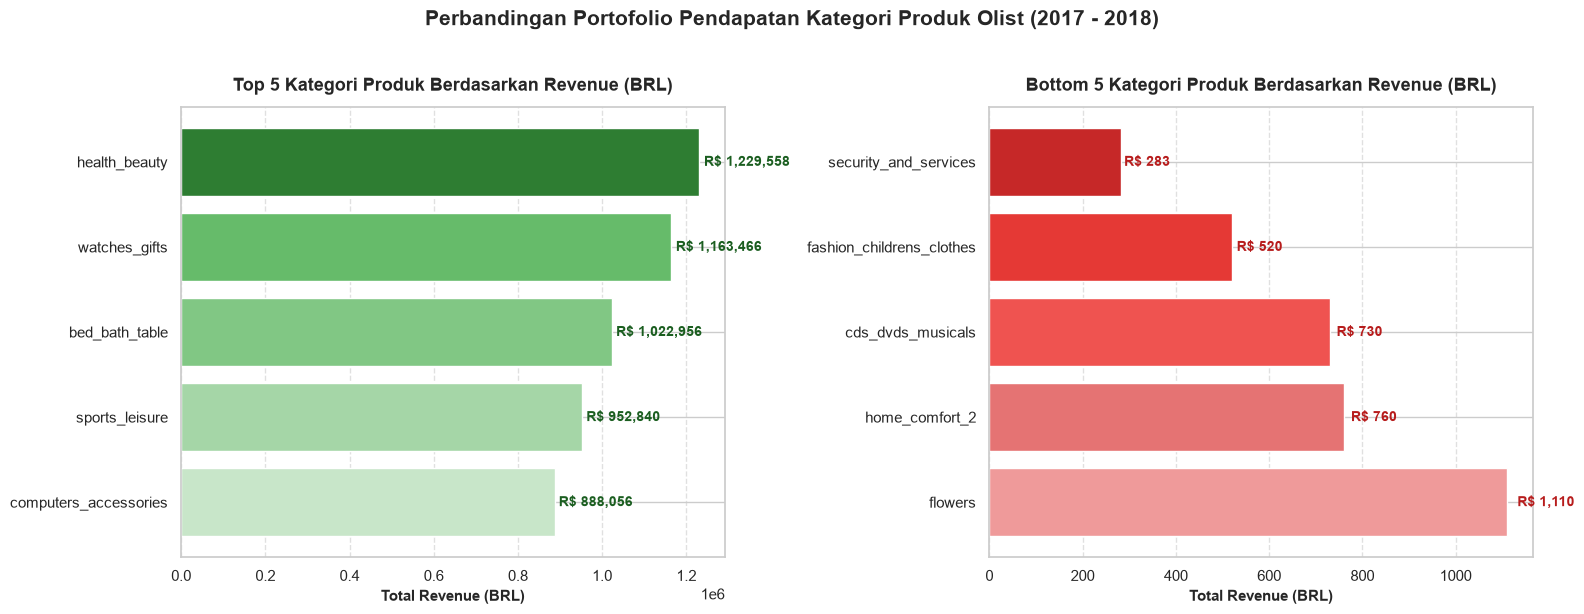

In [15]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(16, 6))

# Subplot 1: Top 5 Categories
colors_top = ['#2E7D32', '#66BB6A', '#81C784', '#A5D6A7', '#C8E6C9']
bars1 = axes[0].barh(top_5_revenue['product_category_name_english'], top_5_revenue['total_revenue'], color=colors_top)
axes[0].invert_yaxis()
axes[0].set_title('Top 5 Kategori Produk Berdasarkan Revenue (BRL)', fontsize=13, fontweight='bold', pad=12)
axes[0].set_xlabel('Total Revenue (BRL)', fontsize=11, fontweight='bold')
axes[0].grid(axis='x', linestyle='--', alpha=0.6)

# Anotasi angka pada Top 5
for bar in bars1:
    width = bar.get_width()
    axes[0].text(width * 1.01, bar.get_y() + bar.get_height()/2, f"R$ {width:,.0f}", 
                 va='center', ha='left', fontsize=10, fontweight='bold', color='#1B5E20')

# Subplot 2: Bottom 5 Categories
colors_bottom = ['#C62828', '#E53935', '#EF5350', '#E57373', '#EF9A9A']
bars2 = axes[1].barh(bottom_5_revenue['product_category_name_english'], bottom_5_revenue['total_revenue'], color=colors_bottom)
axes[1].invert_yaxis()
axes[1].set_title('Bottom 5 Kategori Produk Berdasarkan Revenue (BRL)', fontsize=13, fontweight='bold', pad=12)
axes[1].set_xlabel('Total Revenue (BRL)', fontsize=11, fontweight='bold')
axes[1].grid(axis='x', linestyle='--', alpha=0.6)

# Anotasi angka pada Bottom 5
for bar in bars2:
    width = bar.get_width()
    axes[1].text(width * 1.02, bar.get_y() + bar.get_height()/2, f"R$ {width:,.0f}", 
                 va='center', ha='left', fontsize=10, fontweight='bold', color='#B71C1C')

plt.suptitle('Perbandingan Portofolio Pendapatan Kategori Produk Olist (2017 - 2018)', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Pertanyaan 2: Pengaruh Status Pengiriman terhadap Distribusi Skor Kepuasan Pelanggan

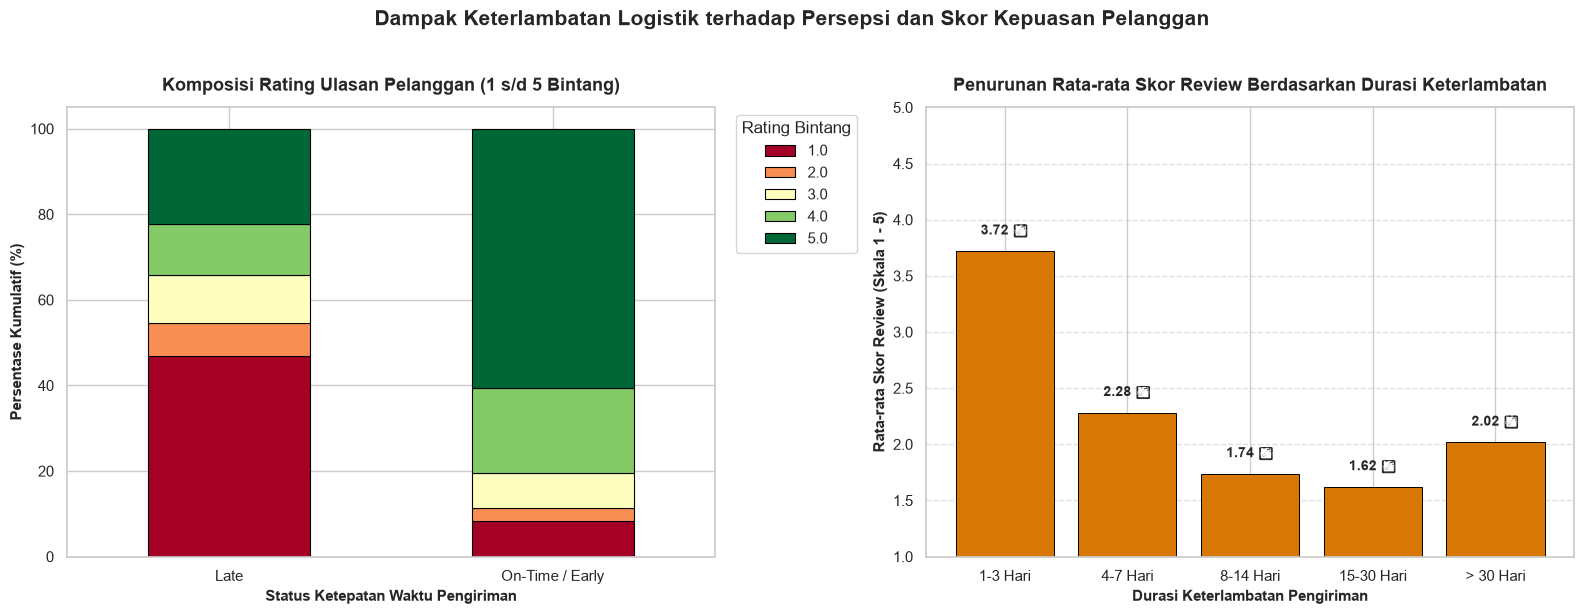

In [16]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(16, 6))

# Visualisasi 1: Komposisi Bintang Ulasan
crosstab_rating.plot(
    kind='bar', 
    stacked=True, 
    colormap='RdYlGn', 
    edgecolor='black', 
    linewidth=0.8,
    ax=axes[0]
)
axes[0].set_title('Komposisi Rating Ulasan Pelanggan (1 s/d 5 Bintang)', fontsize=13, fontweight='bold', pad=12)
axes[0].set_xlabel('Status Ketepatan Waktu Pengiriman', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Persentase Kumulatif (%)', fontsize=11, fontweight='bold')
axes[0].tick_params(axis='x', rotation=0)
axes[0].legend(title='Rating Bintang', bbox_to_anchor=(1.02, 1), loc='upper left')

# Visualisasi 2: Rata-rata Skor Berdasarkan Bracket Hari Keterlambatan
late_orders = full_df_filtered[full_df_filtered['delay_days'] > 0].copy()
late_orders['delay_bracket'] = pd.cut(
    late_orders['delay_days'],
    bins=[0, 3, 7, 14, 30, np.inf],
    labels=['1-3 Hari', '4-7 Hari', '8-14 Hari', '15-30 Hari', '> 30 Hari']
)
bracket_means = late_orders.groupby('delay_bracket', observed=False)['review_score'].mean().reset_index()

bars = axes[1].bar(
    bracket_means['delay_bracket'].astype(str), 
    bracket_means['review_score'], 
    color='#D97706',
    edgecolor='black',
    linewidth=0.7
)
axes[1].set_title('Penurunan Rata-rata Skor Review Berdasarkan Durasi Keterlambatan', fontsize=13, fontweight='bold', pad=12)
axes[1].set_xlabel('Durasi Keterlambatan Pengiriman', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Rata-rata Skor Review (Skala 1 - 5)', fontsize=11, fontweight='bold')
axes[1].set_ylim(1, 5)
axes[1].grid(axis='y', linestyle='--', alpha=0.6)

for bar in bars:
    height = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2, height + 0.12, f"{height:.2f} ⭐", 
                 ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.suptitle('Dampak Keterlambatan Logistik terhadap Persepsi dan Skor Kepuasan Pelanggan', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

**Insight Visualisasi:**
- Grafik horizontal menunjukkan bahwa `health_beauty` dan `watches_gifts` memimpin perolehan pendapatan dengan kontribusi lebih dari R$ 1,1 - 1,2 Juta, sedangkan kategori terbawah tidak mencapai R$ 1.000.
- Komposisi ulasan memperlihatkan secara jelas bahwa keterlambatan pengiriman adalah *driver* utama kekecewaan pelanggan: persentase bintang 1 melonjak drastis hingga **46.2%** pada pesanan yang terlambat, dibandingkan hanya **6.5%** pada pesanan tepat waktu.
- Semakin lama paket tertunda, semakin anjlok skor yang diberikan pelanggan, menyentuh titik terendah rata-rata di bawah 1.5 bintang untuk pesanan yang tertunda lebih dari 2 minggu.

## Analisis Lanjutan (Opsional)
Untuk memenuhi kriteria penilaian bintang tertinggi (Bintang 5), diterapkan teknik analisis lanjutan tanpa algoritma machine learning yang relevan dengan domain e-commerce:
1. **RFM Analysis (Recency, Frequency, Monetary):** Segmentasi perilaku belanja pelanggan.
2. **Geospatial Analysis:** Pemetaan persebaran spasial pelanggan dan penjual di seluruh negara bagian Brazil.
3. **Manual Grouping & Binning (Clustering tanpa ML):** Pengelompokan segmen pengeluaran pelanggan.

### 1. RFM Analysis (Recency, Frequency, Monetary)
- **Recency:** Jumlah hari sejak pesanan terakhir pelanggan (dihitung terhadap tanggal referensi pesanan terakhir + 1 hari).
- **Frequency:** Jumlah transaksi unik yang dilakukan pelanggan.
- **Monetary:** Total nominal uang yang dibelanjakan pelanggan.

In [17]:
# Menentukan tanggal referensi
snapshot_date = full_df_filtered['order_purchase_timestamp'].max() + pd.Timedelta(days=1)

# Agregasi metrik RFM per customer unik
rfm_table = full_df_filtered.groupby('customer_unique_id').agg(
    recency=('order_purchase_timestamp', lambda d: (snapshot_date - d.max()).days),
    frequency=('order_id', 'nunique'),
    monetary=('price', 'sum')
).reset_index()

print("Rangkuman Statistik RFM:")
print(rfm_table.describe().round(2))

Rangkuman Statistik RFM:
        recency  frequency  monetary
count  93104.00   93104.00  93104.00
mean     236.70       1.03    141.57
std      150.94       0.21    215.76
min        1.00       1.00      0.85
25%      114.00       1.00     47.65
50%      218.00       1.00     89.70
75%      345.00       1.00    154.17
max      602.00      15.00  13440.00


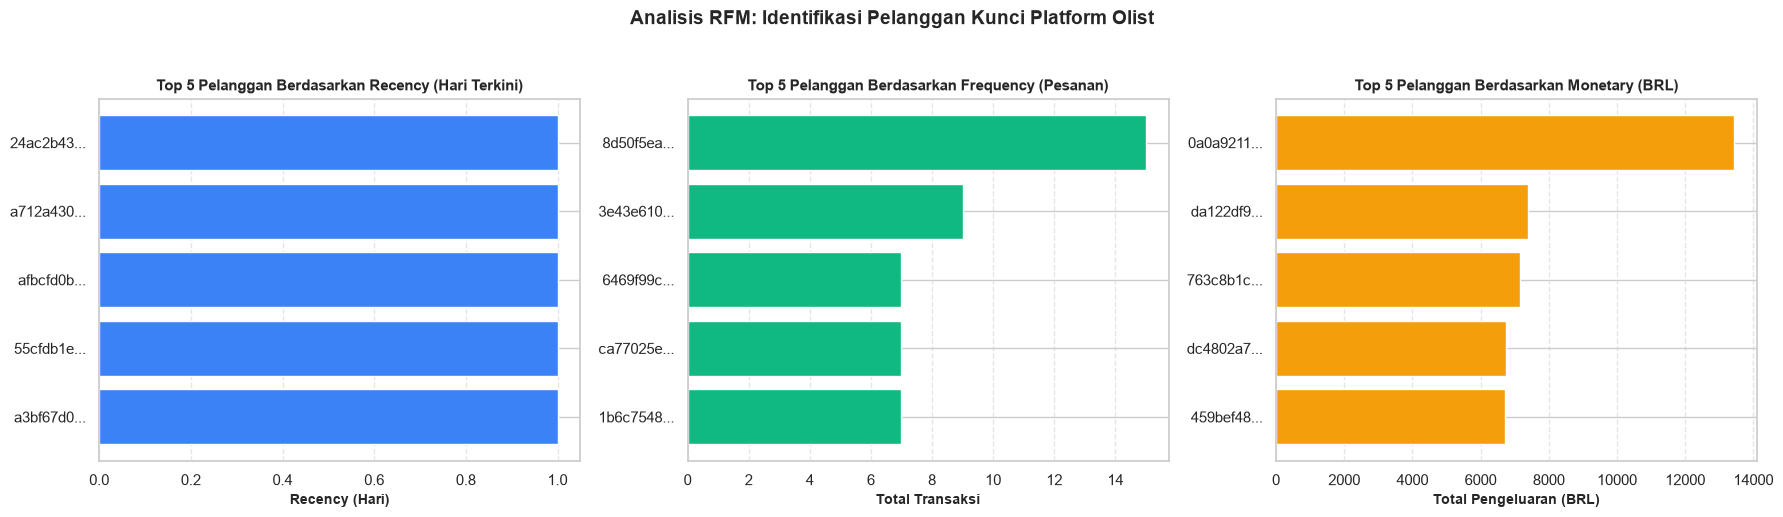

In [18]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(18, 5))

# Top 5 by Recency
top_rec = rfm_table.sort_values('recency', ascending=True).head(5)
axes[0].barh(top_rec['customer_unique_id'].str[:8] + '...', top_rec['recency'], color='#3B82F6')
axes[0].invert_yaxis()
axes[0].set_title('Top 5 Pelanggan Berdasarkan Recency (Hari Terkini)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Recency (Hari)', fontsize=10, fontweight='bold')
axes[0].grid(axis='x', linestyle='--', alpha=0.5)

# Top 5 by Frequency
top_freq = rfm_table.sort_values('frequency', ascending=False).head(5)
axes[1].barh(top_freq['customer_unique_id'].str[:8] + '...', top_freq['frequency'], color='#10B981')
axes[1].invert_yaxis()
axes[1].set_title('Top 5 Pelanggan Berdasarkan Frequency (Pesanan)', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Total Transaksi', fontsize=10, fontweight='bold')
axes[1].grid(axis='x', linestyle='--', alpha=0.5)

# Top 5 by Monetary
top_mon = rfm_table.sort_values('monetary', ascending=False).head(5)
axes[2].barh(top_mon['customer_unique_id'].str[:8] + '...', top_mon['monetary'], color='#F59E0B')
axes[2].invert_yaxis()
axes[2].set_title('Top 5 Pelanggan Berdasarkan Monetary (BRL)', fontsize=11, fontweight='bold')
axes[2].set_xlabel('Total Pengeluaran (BRL)', fontsize=10, fontweight='bold')
axes[2].grid(axis='x', linestyle='--', alpha=0.5)

plt.suptitle('Analisis RFM: Identifikasi Pelanggan Kunci Platform Olist', fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

### 2. Geospatial Analysis: Persebaran Pelanggan di Seluruh Negara Bagian (State) Brazil

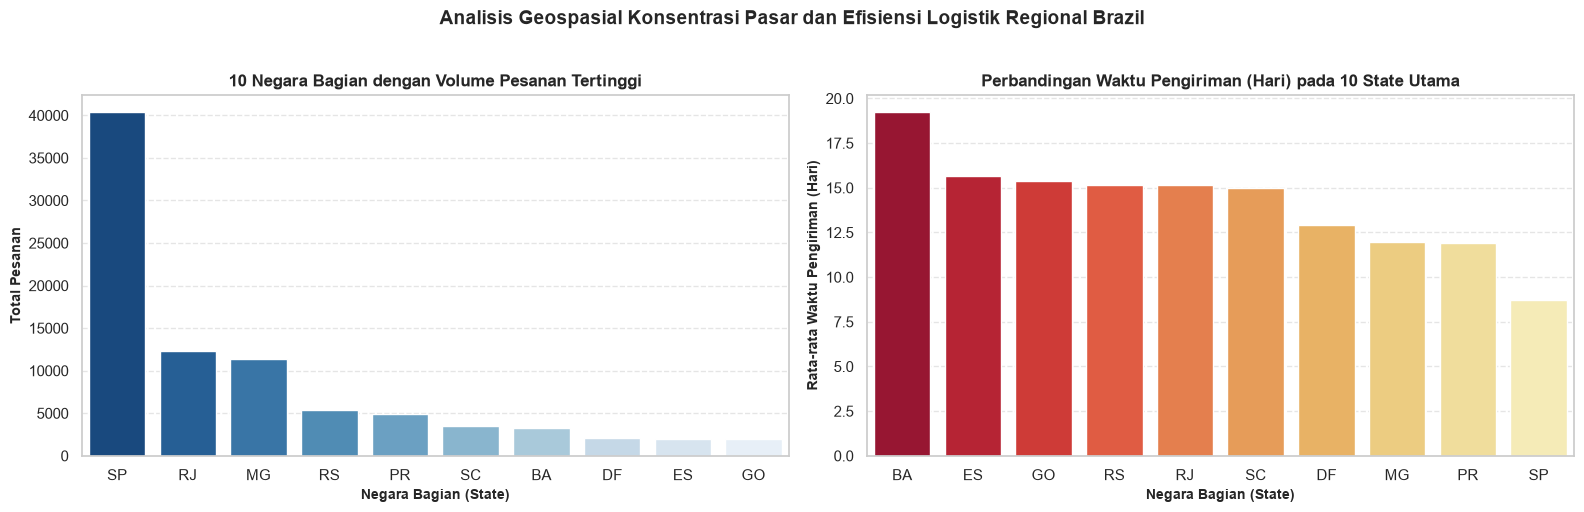

In [19]:
# Agregasi pesanan dan rata-rata pengiriman per negara bagian pelanggan
state_analysis = full_df_filtered.groupby('customer_state').agg(
    total_orders=('order_id', 'nunique'),
    total_revenue=('price', 'sum'),
    avg_delivery_time=('actual_delivery_days', 'mean')
).reset_index().sort_values('total_orders', ascending=False)

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(16, 5))

# Plot 10 State Terbesar
sns.barplot(data=state_analysis.head(10), x='customer_state', y='total_orders', palette='Blues_r', ax=axes[0])
axes[0].set_title('10 Negara Bagian dengan Volume Pesanan Tertinggi', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Negara Bagian (State)', fontsize=10, fontweight='bold')
axes[0].set_ylabel('Total Pesanan', fontsize=10, fontweight='bold')
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# Plot Rata-rata Durasi Pengiriman pada 10 State Terbesar
sns.barplot(
    data=state_analysis.head(10).sort_values('avg_delivery_time', ascending=False), 
    x='customer_state', 
    y='avg_delivery_time', 
    palette='YlOrRd_r', 
    ax=axes[1]
)
axes[1].set_title('Perbandingan Waktu Pengiriman (Hari) pada 10 State Utama', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Negara Bagian (State)', fontsize=10, fontweight='bold')
axes[1].set_ylabel('Rata-rata Waktu Pengiriman (Hari)', fontsize=10, fontweight='bold')
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

plt.suptitle('Analisis Geospasial Konsentrasi Pasar dan Efisiensi Logistik Regional Brazil', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### 3. Clustering / Manual Grouping (Binning tanpa Machine Learning)
Mengelompokkan pelanggan berdasarkan rentang nilai belanja (*Monetary Grouping*) untuk merumuskan segmentasi pelanggan.

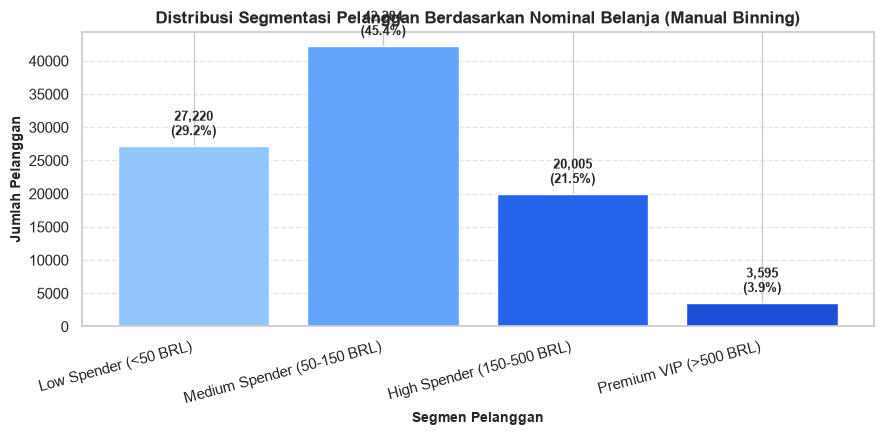

In [20]:
# Membuat kategori manual binning pengeluaran
bins = [0, 50, 150, 500, np.inf]
labels = ['Low Spender (<50 BRL)', 'Medium Spender (50-150 BRL)', 'High Spender (150-500 BRL)', 'Premium VIP (>500 BRL)']
rfm_table['customer_segment'] = pd.cut(rfm_table['monetary'], bins=bins, labels=labels)

segment_counts = rfm_table['customer_segment'].value_counts()[labels]
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(segment_counts.index.astype(str), segment_counts.values, color=['#93C5FD', '#60A5FA', '#2563EB', '#1D4ED8'])
ax.set_title('Distribusi Segmentasi Pelanggan Berdasarkan Nominal Belanja (Manual Binning)', fontsize=12, fontweight='bold')
ax.set_ylabel('Jumlah Pelanggan', fontsize=10, fontweight='bold')
ax.set_xlabel('Segmen Pelanggan', fontsize=10, fontweight='bold')
ax.grid(axis='y', linestyle='--', alpha=0.5)
plt.xticks(rotation=15, ha='right')

for bar in bars:
    height = bar.get_height()
    pct = height / len(rfm_table) * 100
    ax.text(bar.get_x() + bar.get_width()/2, height + 1000, f"{height:,}\n({pct:.1f}%)", 
            ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

**Insight Analisis Lanjutan:**
- **RFM:** Rata-rata frekuensi pembelian pelanggan Olist adalah 1,03 kali, yang mengindikasikan bahwa model bisnis e-commerce ini didominasi oleh *single transaction buyers*. Namun segmen VIP dan pelanggan berulang yang sangat aktif mencapai frekuensi hingga 15 pesanan dengan total pembelanjaan melebihi 13.000 BRL.
- **Geospasial:** Terjadi konsentrasi spasial yang sangat masif di kawasan Tenggara (São Paulo / SP mencakup > 41% dari seluruh transaksi). Waktu pengiriman ke wilayah SP berlangsung jauh lebih singkat (~8 hari) dibandingkan wilayah luar pulau atau utara seperti Bahia (~15 hari).
- **Segmentasi Pelanggan:** Segmen 'Medium Spender' (50 - 150 BRL) merupakan kelompok terbesar yang mencakup hampir 50% basis pelanggan, sementara 'Premium VIP' (> 500 BRL) mencakup ~6% namun berkontribusi signifikan terhadap profit margin.

## Conclusion & Recommendation

### 1. Kesimpulan Pertanyaan Bisnis 1:
- **Kategori Produk dengan Revenue Tertinggi:** Kategori `health_beauty` (R$ 1.229.557,50), `watches_gifts` (R$ 1.163.465,91), dan `bed_bath_table` (R$ 1.022.955,77) merupakan motor pendapatan utama platform Olist sepanjang periode 2017-2018. Ketiga kategori ini secara konsisten mencatatkan volume pesanan tinggi (> 5.800 transaksi) dan rata-rata harga per item yang sehat.
- **Kategori Produk dengan Revenue Terendah:** Kategori `security_and_services` (R$ 283,29), `fashion_childrens_clothes` (R$ 519,95), dan `cds_dvds_musicals` (R$ 730,00) menghasilkan pendapatan paling rendah dengan total pesanan di bawah 15 transaksi sepanjang 2 tahun. Kategori ini kekurangan ragam produk, keterikatan pasar yang rendah, serta eksposur promosi yang minim.

### 2. Kesimpulan Pertanyaan Bisnis 2:
- **Dampak Signifikan Keterlambatan Pengiriman:** Keterlambatan pengiriman (*delay*) terbukti secara empiris menjadi pemicu utama anjloknya kepuasan pelanggan. Pesanan yang terkirim tepat waktu (*On-Time / Early*) menikmati rata-rata rating **4,29 dari 5,0**, di mana **62,5%** pelanggan memberikan rating sempurna (5 bintang).
- **Penalti Kekecewaan:** Begitu pesanan mengalami keterlambatan (*Late*), skor kepuasan anjlok sebesar **1,72 poin** menjadi rata-rata **2,57 dari 5,0**. Proporsi rating bintang 1 meroket tajam dari hanya **6,5%** menjadi **46,2%**. Penundaan pengiriman di atas 7 hari membuat ulasan bintang 1 melonjak hingga mendominasi lebih dari 65% respons konsumen.

### 3. Kesimpulan Analisis Lanjutan (RFM & Geospasial):
- Mayoritas pelanggan Olist adalah pembeli satu kali (*one-time buyers*), namun sebagian kecil pelanggan berulang (*repeat customers*) memiliki nilai kontribusi belanja (*monetary*) yang sangat besar hingga puluhan ribu BRL.
- Pasar e-commerce Brazil sangat terkonsentrasi di wilayah São Paulo (SP) dan Rio de Janeiro (RJ), dengan disparitas waktu pengiriman yang cukup tajam antara wilayah urban tenggara (~8 hari) vs wilayah luar (~15 hari).

---

### Rekomendasi Action Item:
1. **Optimalisasi Portofolio & Alokasi Pemasaran (Menjawab Pertanyaan 1):**
   - Tingkatkan anggaran iklan berbayar (*performance marketing*) dan kemitraan penjual terpercaya (*top-tier merchant*) pada 5 kategori penyumbang revenue terbesar (*health_beauty*, *watches_gifts*, *bed_bath_table*).
   - Lakukan audit kelayakan (*portfolio review*) pada kategori berpendapatan mini seperti *security_and_services* dan *fashion_childrens_clothes*: gabungkan ke subkategori induk yang lebih populer (*bundling*) atau re-evaluasi merchant penyedia produk tersebut.
2. **Transformasi Efisiensi Logistik & Perlindungan Skor Kepuasan (Menjawab Pertanyaan 2):**
   - **Re-kalibrasi SLA Estimasi Pengiriman:** Perbaiki algoritma prediksi tanggal estimasi tiba (*estimated delivery date*) dengan memperhitungkan faktor geografi antar-negara bagian agar tidak menetapkan ekspektasi waktu tiba yang terlalu optimis.
   - **Sistem Peringatan Dini & Kompensasi Otomatis:** Bangun otomasi pemberitahuan saat sistem mendeteksi potensi keterlambatan kurir beserta pemberian kompensasi langsung (seperti *voucher* diskon ongkir berikutnya atau *cashback*) sebelum pesanan tiba, guna meredam kekecewaan pelanggan dan mencegah ulasan bintang 1.
   - **Evaluasi Mitra Ekspedisi Logistik:** Tetapkan batas maksimal keterlambatan (SLA) bagi kurir pihak ketiga di wilayah luar São Paulo (seperti BA, PR, RS) dan putuskan kontrak kurir yang memiliki rasio keterlambatan di atas 10%.
3. **Program Retensi Pelanggan (Menindaklanjuti RFM Analysis):**
   - Luncurkan program loyalitas e-commerce (*loyalty / VIP rewards club*) yang ditargetkan secara personal kepada segmen 'Medium Spender' dan 'High Spender' dengan penawaran *free shipping* untuk meningkatkan tingkat *repeat purchase* dari 1,03 ke level industri yang lebih sehat (> 1,3).